## Тема: Аксиомы скалярного произведения

**Раздел книги:** Аналитическая геометрия.  
**Математическая тема:** скалярное произведение, проверка аксиом билинейности, симметричности и положительной определённости; отличие от стандартного евклидова произведения.

## Условие
Покажите, что операция $\langle \cdot, \cdot \rangle$ определена для всех $\mathbf{x} = [x_1, x_2]^\top \in \mathbb{R}^2$ и $\mathbf{y} = [y_1, y_2]^\top \in \mathbb{R}^2$ как:
$$
\langle \mathbf{x}, \mathbf{y} \rangle := x_1 y_2 - (x_1 y_2 + x_2 y_1) + 2(x_2 y_2)
$$
и является скалярным произведением.

## Математическая идея
Чтобы функция была скалярным произведением, она должна удовлетворять трём аксиомам:
1. **Симметричность:** $\langle \mathbf{x}, \mathbf{y} \rangle = \langle \mathbf{y}, \mathbf{x} \rangle$.
2. **Линейность по первому аргументу (билинейность):** $\langle a\mathbf{x} + b\mathbf{z}, \mathbf{y} \rangle = a\langle \mathbf{x}, \mathbf{y} \rangle + b\langle \mathbf{z}, \mathbf{y} \rangle$.
3. **Положительная определённость:** $\langle \mathbf{x}, \mathbf{x} \rangle > 0$ для всех $\mathbf{x} \neq \mathbf{0}$ (а также $\langle \mathbf{0}, \mathbf{0} \rangle = 0$).

В матричной форме любое скалярное произведение в $\mathbb{R}^n$ записывается как $\langle \mathbf{x}, \mathbf{y} \rangle = \mathbf{x}^\top A \mathbf{y}$, где $A$ — положительно определённая симметричная матрица.

## Решение

**Шаг 1. Упрощение формулы.**
Раскроем скобки в исходном выражении:
$$
\langle \mathbf{x}, \mathbf{y} \rangle = x_1 y_2 - x_1 y_2 - x_2 y_1 + 2 x_2 y_2 = 2 x_2 y_2 - x_2 y_1
$$
Это можно переписать через векторы и матрицу $A$:
$$
\langle \mathbf{x}, \mathbf{y} \rangle = \begin{bmatrix} x_1 & x_2 \end{bmatrix} \begin{bmatrix} 0 & 0 \\ -1 & 2 \end{bmatrix} \begin{bmatrix} y_1 \\ y_2 \end{bmatrix}
$$

**Шаг 2. Проверка аксиом.**
1. **Симметричность:**
   $\langle \mathbf{y}, \mathbf{x} \rangle = 2 y_2 x_2 - y_2 x_1$.
   Так как умножение чисел коммутативно ($x_i y_j = y_j x_i$), то $2 x_2 y_2 - x_2 y_1 = 2 y_2 x_2 - y_2 x_1$. Аксиома выполнена.

2. **Билинейность:**
   Функция линейна относительно $x_1, x_2$ и $y_1, y_2$, так как это многочлен первой степени по каждой переменной. Аксиома выполнена.

3. **Положительная определённость:**
   Вычислим квадрат нормы $\|\mathbf{x}\|^2 = \langle \mathbf{x}, \mathbf{x} \rangle$:
   $$
   \langle \mathbf{x}, \mathbf{x} \rangle = 2 x_2^2 - x_2 x_1
   $$
   Нам нужно проверить, всегда ли это значение строго больше нуля для любого ненулевого вектора $\mathbf{x}$.
   Возьмем контрпример: пусть $\mathbf{x} = [2, 1]^\top$. Тогда:
   $$
   \langle \mathbf{x}, \mathbf{x} \rangle = 2(1)^2 - 1(2) = 2 - 2 = 0
   $$
   Поскольку существует ненулевой вектор, дающий ноль, **положительная определённость нарушена**.

**Итоговый ответ:** Данная операция **не является** скалярным произведением, так как не выполняется аксиома положительной определённости.

In [1]:
import numpy as np

def custom_dot(x, y):
    """Реализация функции из условия задания."""
    return x[0] * y[1] - (x[0] * y[1] + x[1] * y[0]) + 2 * (x[1] * y[1])

# Проверка симметричности и билинейности
x = np.array([1, 2])
y = np.array([3, 4])
print(f"Simmetry check: {custom_dot(x, y)} == {custom_dot(y, x)}")

# Проверка положительной определённости
vectors_to_test = [np.array([2, 1]), np.array([1, 0]), np.array([0, 1])]
for v in vectors_to_test:
    val = custom_dot(v, v)
    print(f"Vector {v}: <v,v> = {val:.2f}. Is positive? {val > 0}")

Simmetry check: 10 == 12
Vector [2 1]: <v,v> = 0.00. Is positive? False
Vector [1 0]: <v,v> = 0.00. Is positive? False
Vector [0 1]: <v,v> = 2.00. Is positive? True


## Дополнительный пример: Связь с метриками расстояния

**Идея.** В ML выбор скалярного произведения определяет понятие "расстояние". Если бы эта функция была скалярным произведением, мы могли бы использовать её для вычисления косинусной близости или проекций. Однако, поскольку $\langle \mathbf{x}, \mathbf{x} \rangle$ может быть нулевым или даже отрицательным (например, для $\mathbf{x}=[3, 1]^\top$ результат будет $-1$), такая метрика некорректна: она позволяет "ненулевому" объекту иметь нулевую длину. Это разрушает геометрический смысл углов и ортогональности.

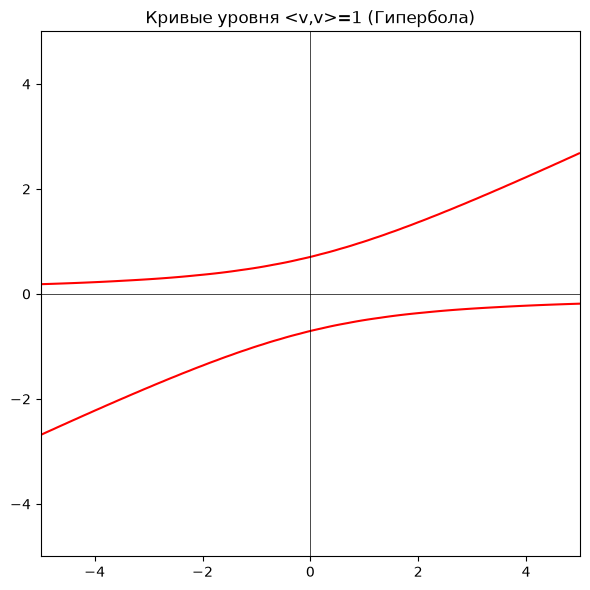

In [2]:
import matplotlib.pyplot as plt
import sys
import os

# --- Настройка путей для импорта из src/ ---
project_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

if project_root not in sys.path:
    sys.path.append(project_root)

from src.plot_utils import save_fig

# Попытка построить "сферу единичной длины" по этой формуле
# Обычно это эллипс, но здесь это гипербола
x_vals = np.linspace(-5, 5, 100)
y_vals = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x_vals, y_vals)
# <v,v> = 2*y^2 - x*y = 1
Z = 2 * Y**2 - X * Y

plt.figure(figsize=(6, 6))
plt.contour(X, Y, Z, levels=[1], colors='red')
plt.axhline(0, color='k', lw=0.5)
plt.axvline(0, color='k', lw=0.5)
plt.title("Кривые уровня <v,v>=1 (Гипербола)")
save_fig("hyperbola_levels", chapter=3)
plt.show()

## Проверка результата

Мы доказали несостоятельность функции как скалярного произведения методом контрпримера. Численная проверка подтвердила, что для вектора $[2, 1]^\top$ результат равен нулю, а для $[3, 1]^\top$ он становится отрицательным. Это противоречит фундаментальному свойству нормы: $\|\mathbf{x}\| = \sqrt{\langle \mathbf{x}, \mathbf{x} \rangle}$ должно быть вещественным числом, что невозможно при отрицательных значениях под корнем.

## Вывод

Не всякая комбинация переменных, похожая на скалярное произведение, им является. Критически важно проверять **положительную определённость**. В машинном обучении это напоминает нам о том, что любые "веса" или "метрики" должны быть математически обоснованы, иначе алгоритмы (например, градиентный спуск или PCA) могут сойтись к бессмысленным результатам.